#  Modified Z-Score

In [11]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
# Generate clean data plus a cluster of outliers that masks the mean
np.random.seed(42)

# 200 normal points around 50
clean = np.random.normal(loc=50, scale=2, size=200)

# 20 clustered outliers around 70 (enough to inflate mean and std)
masking_outliers = np.random.normal(loc=70, scale=1, size=20)

all_values = np.concatenate([clean, masking_outliers])

# Build DataFrame
df = pd.DataFrame({"value": all_values})
print(df.describe())

            value
count  220.000000
mean    51.782593
std      6.177370
min     44.760510
25%     48.798189
50%     50.210574
75%     51.592811
max     73.852731


In [13]:
#  Compute median, MAD and Modified Z-Score
# Calculate median of the column
median_val = df["value"].median()

# Calculate MAD: median of absolute deviations from median
mad = (df["value"] - median_val).abs().median()

print(f"Median: {median_val:.2f}, MAD: {mad:.2f}")

# Guard against MAD = 0 (identical majority values)
if mad == 0:
    print("MAD is zero: data has no variation around median, use IQR instead.")
    df["mod_z"] = 0.0
else:
    # Compute Modified Z-Score with 0.6745 consistency constant
    df["mod_z"] = 0.6745 * (df["value"] - median_val) / mad

# Flag outliers with recommended threshold 3.5
df["is_outlier_mad"] = df["mod_z"].abs() > 3.5

print(f"Detected by Modified Z-Score: {df['is_outlier_mad'].sum()}")

# Compare with Standard Z-Score that suffers from masking
mean_val = df["value"].mean()
std_val = df["value"].std()
df["z_std"] = (df["value"] - mean_val) / std_val
df["is_outlier_std"] = df["z_std"].abs() > 3

print(f"Mean: {mean_val:.2f}, Std: {std_val:.2f}")
print(f"Detected by Standard Z-Score: {df['is_outlier_std'].sum()}")

Median: 50.21, MAD: 1.41
Detected by Modified Z-Score: 20
Mean: 51.78, Std: 6.18
Detected by Standard Z-Score: 13


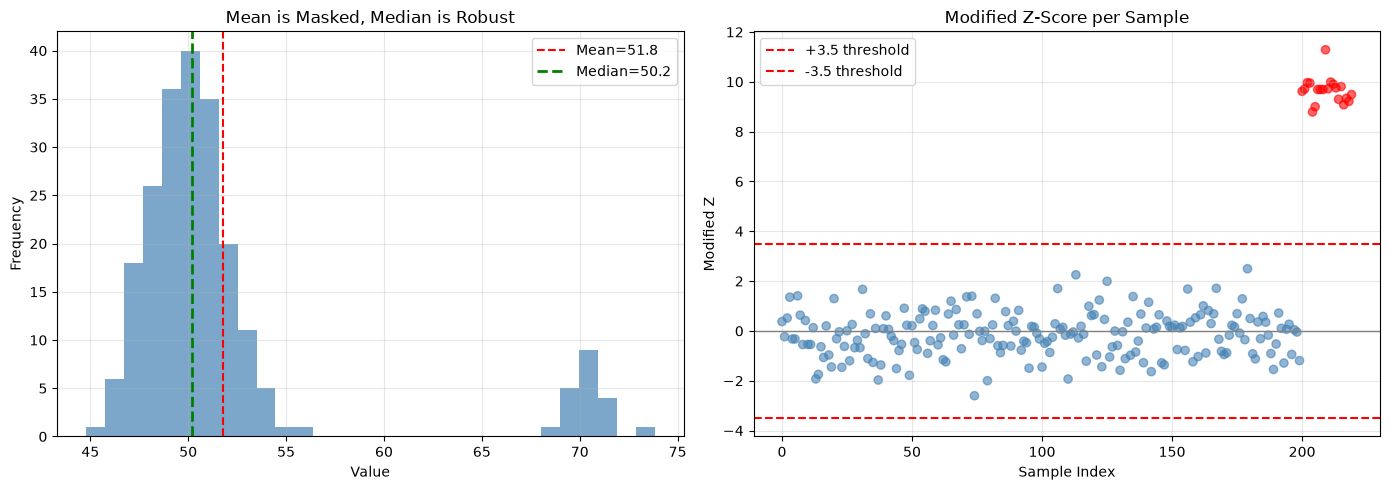

In [14]:
# Visualize masking effect and Modified Z-Scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: histogram shows mean is pulled but median stays
axes[0].hist(df["value"], bins=30, color="steelblue", alpha=0.7)
axes[0].axvline(mean_val, color="red", linestyle="--", label=f"Mean={mean_val:.1f}")
axes[0].axvline(median_val, color="green", linestyle="--", linewidth=2, label=f"Median={median_val:.1f}")
axes[0].set_title("Mean is Masked, Median is Robust")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right plot: Modified Z-Score per sample
x_pos = np.arange(len(df))
colors = np.where(df["is_outlier_mad"], "red", "steelblue")
axes[1].scatter(x_pos, df["mod_z"], c=colors, alpha=0.6)
axes[1].axhline(3.5, color="red", linestyle="--", label="+3.5 threshold")
axes[1].axhline(-3.5, color="red", linestyle="--", label="-3.5 threshold")
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set_title("Modified Z-Score per Sample")
axes[1].set_xlabel("Sample Index")
axes[1].set_ylabel("Modified Z")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Experiment - compare Standard Z, IQR and Modified Z on masked data
# IQR baseline on the same data
Q1 = df["value"].quantile(0.25)
Q3 = df["value"].quantile(0.75)
IQR = Q3 - Q1
iqr_count = (((df["value"] < Q1 - 1.5 * IQR) | (df["value"] > Q3 + 1.5 * IQR))).sum()

print(f"Standard Z-Score: {df['is_outlier_std'].sum()} outliers")
print(f"IQR: {iqr_count} outliers")
print(f"Modified Z-Score: {df['is_outlier_mad'].sum()} outliers")
# Question: Why did Standard Z-Score miss most of the 20 injected points?
# Hint: Check how much the 20 points inflated the mean and std.

Standard Z-Score: 13 outliers
IQR: 20 outliers
Modified Z-Score: 20 outliers
